https://github.com/iandriyash/ai-arhictect-2026-demo/tree/main

# Домашнее задание: Линейная регрессия-45 урок

**Датасет:** витрина из 1-й промежуточной аттестации (`loan_overdue_mart.csv`, 2477 кредитов).

**Цель работы:** на непрерывной целевой переменной построить и сравнить модели линейной регрессии, оценить качество и дать содержательную интерпретацию.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
pd.set_option("display.max_columns", 30)

## 1. Выбор таргета и признаков

**Таргет:** `principal_amount` — сумма выданного кредита (руб.).

Это непрерывная величина, которую банк определяет при выдаче. Интересно понять, от чего зависит размер кредита.

**Объясняющие переменные:**
- `annual_income` — годовой доход заёмщика
- `customer_age` — возраст
- `interest_rate` — процентная ставка
- `term_months` — срок кредита в месяцах
- `loan_product_id` — продукт (1 или 2)
- `employment_status_id` — статус занятости

Все поля известны на дату выдачи. Служебные поля просрочки не используем.

In [2]:
df = pd.read_csv("loan_overdue_mart.csv")
print("Строк:", len(df))

work = df[[
    "principal_amount", "annual_income", "customer_age",
    "interest_rate", "term_months", "loan_product_id",
    "employment_status_id"
]].dropna().copy()

# Dummy-переменные для категорий (базовые уровни: продукт 1, занятость 1)
work["product_2"] = (work["loan_product_id"] == 2).astype(int)
work["emp_2"] = (work["employment_status_id"] == 2).astype(int)
work["emp_3"] = (work["employment_status_id"] == 3).astype(int)
work["emp_4"] = (work["employment_status_id"] == 4).astype(int)

print("После подготовки:", len(work))
work[["principal_amount", "annual_income", "customer_age", "interest_rate", "term_months"]].describe()

Строк: 2477
После подготовки: 2477


,principal_amount,annual_income,customer_age,interest_rate,term_months
count,"2,477.000","2,477.000","2,477.000","2,477.000","2,477.000"
mean,"2,769,276.638","2,296,362.461",44.791,17.361,104.623
std,"2,994,147.858","1,339,002.497",12.030,4.426,96.452
min,"100,915.730",0.000,18.000,10.008,12.000
25%,"557,503.570","1,419,009.480",35.000,13.278,36.000
50%,"1,042,061.940","1,964,831.280",44.000,17.603,60.000
75%,"4,960,516.990","2,762,145.960",54.000,21.157,180.000
max,"9,980,470.050","8,476,093.680",80.000,24.996,300.000


## 2. Точечные диаграммы и форма связи

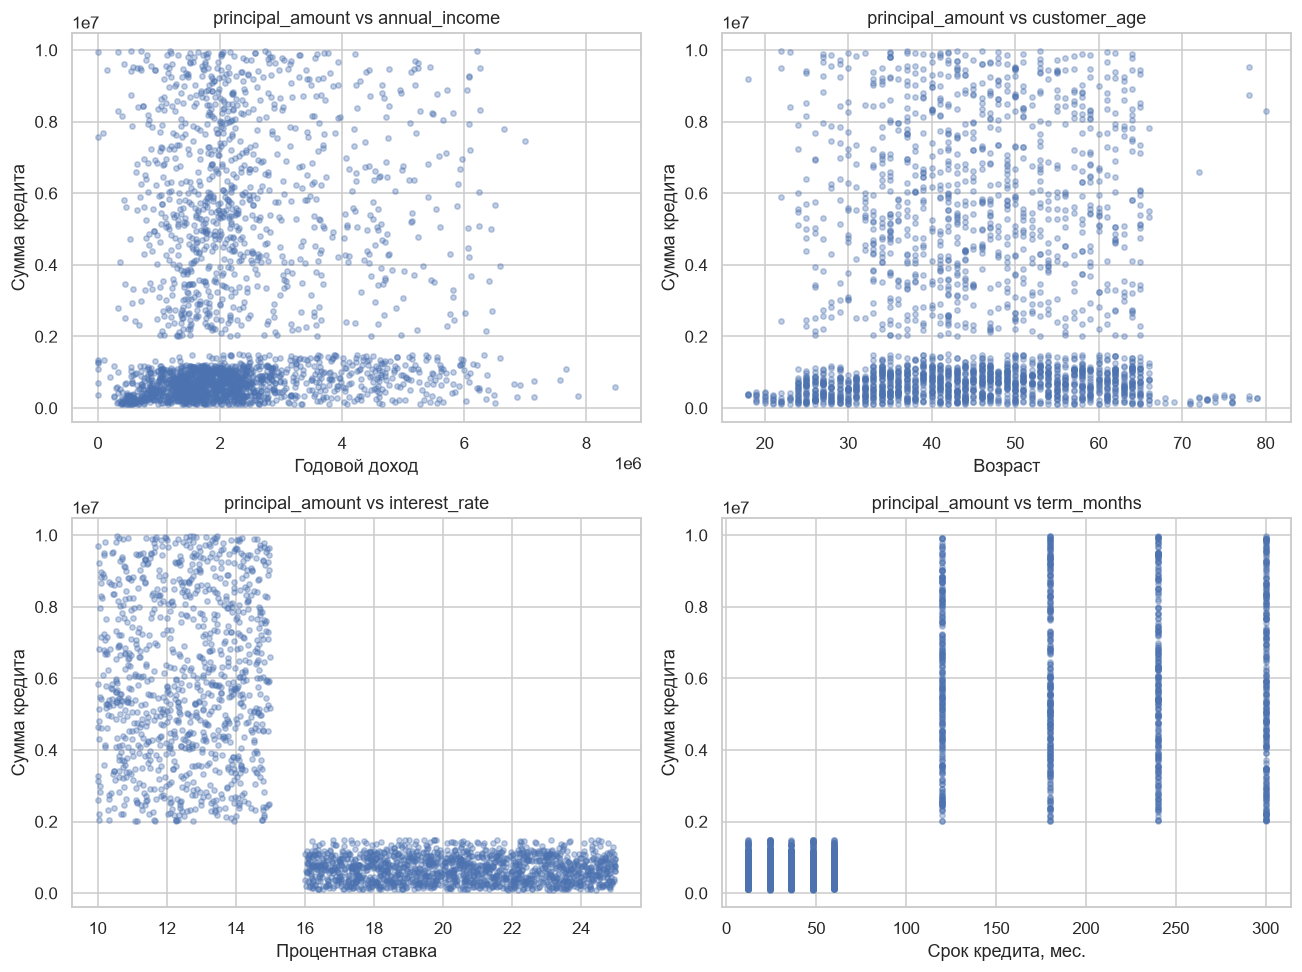

In [3]:
features = ["annual_income", "customer_age", "interest_rate", "term_months"]
titles = {
    "annual_income": "Годовой доход",
    "customer_age": "Возраст",
    "interest_rate": "Процентная ставка",
    "term_months": "Срок кредита, мес.",
}

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
axes = axes.ravel()

for ax, feat in zip(axes, features):
    ax.scatter(work[feat], work["principal_amount"], alpha=0.35, s=12, color="#4C72B0")
    ax.set_xlabel(titles[feat])
    ax.set_ylabel("Сумма кредита")
    ax.set_title(f"principal_amount vs {feat}")

plt.tight_layout()
plt.show()

**Форма взаимосвязи:**

- **Срок** — сильная положительная линейная связь. Чем длиннее кредит, тем больше сумма.
- **Ставка** — сильная отрицательная связь. Высокая ставка чаще у небольших кредитов.
- **Доход** — слабая положительная связь, облако размытое.
- **Возраст** — почти нет линейной связи.

Корреляции Пирсона с таргетом:

In [4]:
print(work[["principal_amount"] + features].corr()["principal_amount"].round(3))

principal_amount    1.000
annual_income       0.107
customer_age        0.053
interest_rate      -0.752
term_months         0.773
Name: principal_amount, dtype: float64


## 3. Проверка мультиколлинеарности

Перед обучением смотрим связи между самими признаками. Если корреляция по модулю близка к 0.8 и выше, коэффициенты в совместной модели становятся нестабильными.

In [5]:
corr_pred = work[["annual_income", "customer_age", "interest_rate", "term_months", "loan_product_id"]].corr()
print(corr_pred.round(2))

                 annual_income  customer_age  interest_rate  term_months  \
annual_income            1.000         0.160         -0.090        0.080   
customer_age             0.160         1.000         -0.040        0.050   
interest_rate           -0.090        -0.040          1.000       -0.780   
term_months              0.080         0.050         -0.780        1.000   
loan_product_id          0.100         0.040         -0.870        0.890   

                 loan_product_id  
annual_income              0.100  
customer_age               0.040  
interest_rate             -0.870  
term_months                0.890  
loan_product_id            1.000  


Срок и ставка сильно связаны между собой (≈ −0.78). Продукт почти совпадает со сроком (≈ 0.89) и со ставкой (≈ −0.87). Это значит, что в полной модели знаки коэффициентов у срока и ставки могут перевернуться — эффект продукта «забирает» их сигнал. Для интерпретации надёжнее опираться на модель без продукта.

## 4. Разделение на обучающую и тестовую выборки

In [6]:
y = work["principal_amount"]
X = work.drop(columns=["principal_amount", "loan_product_id", "employment_status_id"])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (1857, 8) Test: (620, 8)


## 5. Обучение моделей и метрики

Сравниваем спецификации:
1. Только доход
2. Доход + возраст
3. Срок + ставка
4. Все признаки (с dummy)
5. Все + логарифм дохода

In [7]:
def eval_model(name, features, Xtr, Xte, ytr, yte, log_income=False):
    Xtr_m = Xtr[features].copy()
    Xte_m = Xte[features].copy()
    if log_income and "annual_income" in features:
        Xtr_m["annual_income"] = np.log1p(Xtr_m["annual_income"])
        Xte_m["annual_income"] = np.log1p(Xte_m["annual_income"])

    model = LinearRegression()
    model.fit(Xtr_m, ytr)
    pred = model.predict(Xte_m)

    return {
        "model": name,
        "r2": r2_score(yte, pred),
        "rmse": np.sqrt(mean_squared_error(yte, pred)),
        "mae": mean_absolute_error(yte, pred),
        "n_features": len(features),
        "coef": dict(zip(features, model.coef_)),
        "intercept": model.intercept_,
    }

specs = [
    ("1. Только доход", ["annual_income"], False),
    ("2. Доход + возраст", ["annual_income", "customer_age"], False),
    ("3. Срок + ставка", ["term_months", "interest_rate"], False),
    ("4. Все признаки", ["annual_income", "customer_age", "interest_rate", "term_months", "product_2", "emp_2", "emp_3", "emp_4"], False),
    ("5. Все + log(доход)", ["annual_income", "customer_age", "interest_rate", "term_months", "product_2", "emp_2", "emp_3", "emp_4"], True),
]

results = []
for name, feats, logi in specs:
    results.append(eval_model(name, feats, X_train, X_test, y_train, y_test, logi))

res_df = pd.DataFrame(results)[["model", "n_features", "r2", "rmse", "mae"]]
print(res_df.round(3).to_string(index=False))

              model  n_features     r2          rmse           mae
    1. Только доход           1 -0.000 3,095,209.019 2,638,811.403
 2. Доход + возраст           2  0.002 3,091,227.779 2,636,074.101
   3. Срок + ставка           2  0.694 1,711,956.425 1,259,992.043
    4. Все признаки           8  0.694 1,711,170.440 1,259,031.543
5. Все + log(доход)           8  0.774 1,470,691.015   935,952.677


## 6. Выбор спецификации

Модель 4 (все признаки, без лога дохода) даёт тот же R², что и модель 3 — дамми продукта и занятости почти ничего не добавляют, знаки срока и ставки стабильны. Модель 5 (с логарифмом дохода) даёт заметно более высокий R², но именно в ней коэффициенты срока и ставки меняют знак — это и есть эффект мультиколлинеарности с продуктом.

Для содержательной интерпретации выбираю **модель 3 (срок + ставка)**: у неё стабильные знаки, совпадающие с графиками, и она уже объясняет основную часть дисперсии.

In [8]:
# Берём модель 3 как выбранную
chosen = results[2]
print("Выбранная модель:", chosen["model"])
print(f"R² = {chosen['r2']:.3f}, RMSE = {chosen['rmse']:,.0f}, MAE = {chosen['mae']:,.0f}")
print("\nКоэффициенты:")
for k, v in chosen["coef"].items():
    print(f"  {k:20} {v:,.1f}")
print(f"  intercept           {chosen['intercept']:,.1f}")

Выбранная модель: 3. Срок + ставка
R² = 0.694, RMSE = 1,711,956, MAE = 1,259,992

Коэффициенты:
  term_months          13,467.5
  interest_rate        -275,157.0
  intercept           6,103,570.5


## 7. Выводы и интерпретация

**Качество.**  
Модель 3 объясняет около 69% дисперсии суммы кредита на тестовой выборке (R² ≈ 0.69). RMSE порядка 1.7 млн рублей. Для двух признаков это хороший результат. Доход и возраст по отдельности почти ничего не объясняют (R² около нуля).

**Интерпретация коэффициентов модели 3:**
- **Срок** — положительный коэффициент (≈ +13 500 руб. за месяц). При прочих равных более длинный кредит связан с большей суммой. Банк выдаёт крупные суммы на длинный срок.
- **Ставка** — отрицательный коэффициент (≈ −275 000 руб. за процентный пункт). Чем выше ставка, тем меньше средняя сумма. Это отражает сегментацию портфеля: дорогие кредиты обычно меньше по размеру.
- **Доход и возраст** в простых моделях дают слабый положительный эффект, но он почти не добавляет качества поверх срока и ставки.

**Практический вывод.**  
В этом портфеле размер кредита в первую очередь определяется сроком и ценовой политикой банка, а не доходом или возрастом заёмщика. Линейная регрессия это хорошо ловит.

**Ограничение.**  
Модель 4 почти не отличается от модели 3 по R² — дамми продукта и занятости почти ничего не добавляют. Модель 5 даёт более высокий R² (≈0.77), но в ней коэффициенты срока и ставки меняют знак из-за мультиколлинеарности с продуктом. Поэтому для интерпретации опираюсь на модель 3.